Гиперпарамтеры данного ноутбука

In [36]:
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

SEED = 42
K = 10
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, torch.get_num_threads()))

CONFIG = {
    "seed": SEED,
    "k": K,
    "n_users": 60_000,    
    "min_user_items": 5, 
    "min_item_users": 10,
    "train_end_day": 20,
    "val_end_day": 25,
    "movie_completion": 0.5,
    "series_completion": 1.0,
    "like_rating": 8,
    "dislike_rating": 4,
    "main_metric": f"NDCG@{K}",
    "n_trials": {"knn": 20, "ease": 12, "ials": 20, "fm": 12, "timesvdpp": 12},
    "cache_dir": "cache", 
}
CONFIG

{'seed': 42,
 'k': 10,
 'n_users': 60000,
 'min_user_items': 5,
 'min_item_users': 10,
 'train_end_day': 20,
 'val_end_day': 25,
 'movie_completion': 0.5,
 'series_completion': 1.0,
 'like_rating': 8,
 'dislike_rating': 4,
 'main_metric': 'NDCG@10',
 'n_trials': {'knn': 20, 'ease': 12, 'ials': 20, 'fm': 12, 'timesvdpp': 12},
 'cache_dir': 'cache'}

## Просмотр датасета

Загрузим руками данные из кагла и положим распакуем их в /data/raw. Далее используем функции из src/data для работы с ними

In [37]:
from src.data import (load_raw, prepare_interactions, make_subsample, temporal_split,
                      is_completed, is_relevant)

t = time.time()
raw = load_raw()
for name, frame in raw.items():
    print(f"{name:13s} {frame.shape}")

transactions  (9643012, 7)
ratings       (438790, 4)
bookmarks     (948216, 3)
catalogue     (10200, 9)


посмортим на данные

In [38]:
files = {
    "transactions": ("transactions.csv", "просмотры"),
    "ratings": ("ratings.csv", "оценки 0–10"),
    "bookmarks": ("bookmarks.csv", "закладки"),
    "catalogue": ("catalogue.json", "каталог объектов"),
}
for name, (file, what) in files.items():
    print(f"\n=== {file} — {what} (raw['{name}'])")
    display(raw[name].head(3))


=== transactions.csv — просмотры (raw['transactions'])


,element_uid,user_uid,consumption_mode,ts,watched_time,device_type,device_manufacturer
0,3336,5177,S,4.430518e+07,4282,0,50
1,481,593316,S,4.430518e+07,2989,0,11
2,4128,262355,S,4.430518e+07,833,0,50



=== ratings.csv — оценки 0–10 (raw['ratings'])


,user_uid,element_uid,rating,ts
0,571252,1364,10,4.430517e+07
1,63140,3037,10,4.430514e+07
2,443817,4363,8,4.430514e+07



=== bookmarks.csv — закладки (raw['bookmarks'])


,user_uid,element_uid,ts
0,301135,7185,4.430516e+07
1,301135,4083,4.430516e+07
2,301135,10158,4.430516e+07



=== catalogue.json — каталог объектов (raw['catalogue'])


,type,availability,duration,feature_1,feature_2,feature_3,feature_4,feature_5,attributes
element_uid,,,,,,,,,
0,movie,[],80,2.912198e+07,0.575260,0,1.128332,0.654707,"[31115, 6713, 10906, 31116, 31117, 270, 24431,..."
1,movie,"[purchase, rent]",120,6.610431e+06,0.773224,3,1.112014,0.654707,"[2786, 385, 2799, 3730, 886, 7, 11700, 42, 20,..."
2,movie,[],80,1.315874e+07,0.699502,0,1.110127,0.680410,"[31442, 31443, 31444, 31445, 113, 31446, 42, 3..."


**transactions.csv** — это просмотры (одна строка на пару пользователь–объект):

| Поле | Смысл |
|---|---|
| `user_uid`, `element_uid` | идентификаторы юзера и айтема |
| `consumption_mode` | способ потребления: `S` — подписка, `P` — покупка, `R` — аренда |
| `ts` | время события |
| `watched_time` | суммарное время просмотра |
| `device_type`, `device_manufacturer` | тип устройтсва и производитель|

**ratings.csv** — оценки по шкале 0–10 (`user_uid`, `element_uid`, `rating`, `ts`);
**bookmarks.csv** — добавления в закладки (`user_uid`, `element_uid`, `ts`).

**catalogue.json** — каталог: `type` (movie / series / multipart_movie), `availability`
(доступность по покупке / аренде / подписке), `duration` (длительность в минутах),
`feature_1..5` (анонимные признаки), `attributes` (анонимные айди атрибутов).

Будем рекомендовать юзеру топ-10 сериалов/фильмов/видео которые он посмотрит. \\
Релевантныыми считаем рекомендации для которых верно: 

$$
\text{rel}(u,i) = \big(\text{досмотр}(u,i)\ \lor\ \text{rating}_{ui} \ge 8\big)\ \land\ (\text{rating}_{ui} > 4\big),
$$

где досмотр — фильм просмотрен не меньше чем на половину, сериал/многосерийный фильм — не меньше одной серии. Начатый и брошенный просмотр релевантным не считается.

## Подготовка и первичный анализ данных

проверим данные на пропуски, повторы

In [39]:
tr_raw, r_raw, b_raw, cat = raw["transactions"], raw["ratings"], raw["bookmarks"], raw["catalogue"]
summary = pd.DataFrame({
    "строк": [len(tr_raw), len(r_raw), len(b_raw), len(cat)],
    "пользователей": [tr_raw.user_uid.nunique(), r_raw.user_uid.nunique(), b_raw.user_uid.nunique(), None],
    "объектов": [tr_raw.element_uid.nunique(), r_raw.element_uid.nunique(), b_raw.element_uid.nunique(), len(cat)],
    "пропусков": [int(tr_raw.isna().sum().sum()), int(r_raw.isna().sum().sum()),
                  int(b_raw.isna().sum().sum()), int(cat.drop(columns=["attributes", "availability"]).isna().sum().sum())],
    "полных дубликатов": [tr_raw.duplicated().sum(), r_raw.duplicated().sum(), b_raw.duplicated().sum(), None],
    "дубликатов пары (u,i)": [tr_raw.duplicated(["user_uid", "element_uid"]).sum(),
                              r_raw.duplicated(["user_uid", "element_uid"]).sum(),
                              b_raw.duplicated(["user_uid", "element_uid"]).sum(), None],
}, index=["transactions", "ratings", "bookmarks", "catalogue"])
display(summary)
print("Объекты transactions без записи в каталоге:", (~tr_raw.element_uid.isin(cat.index)).sum())
print(f"Период лога: {(tr_raw.ts.max() - tr_raw.ts.min()) / 86400:.1f} дней")

,строк,пользователей,объектов,пропусков,полных дубликатов,"дубликатов пары (u,i)"
transactions,9643012,499663.0,8296,0,0.0,0.0
ratings,438790,104563.0,7519,0,0.0,0.0
bookmarks,948216,147167.0,9489,0,0.0,0.0
catalogue,10200,NaN,10200,0,NaN,NaN


Объекты transactions без записи в каталоге: 0
Период лога: 29.8 дней


Сведем весь датасет к единой таблице (добавив колонки, показывающие релевантность по нашим критериям), при этом удалим все объекты с нулевой длительностью из нашего датасета.

In [40]:
df = prepare_interactions(**raw)
df["completed"] = is_completed(df, CONFIG["movie_completion"], CONFIG["series_completion"])
df["relevant"] = is_relevant(df, CONFIG["like_rating"], CONFIG["dislike_rating"])
print(df.shape)
print("Объектов с нулевой длительностью в каталоге:",
      int((cat["duration"] <= 0).sum()))
display(df.head())
display(df.groupby("item_type")["watch_ratio"].describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

(9537199, 17)
Объектов с нулевой длительностью в каталоге: 114


,item_id,user_id,consumption_mode,ts,watched_time,device_type,device_manufacturer,day,item_type,duration_sec,watch_ratio,rating,rating_ts,bookmark_ts,bookmarked,completed,relevant
0,3336,5177,S,4.430518e+07,4282,0,50,29,movie,5400.0,0.792963,9.0,4.430415e+07,NaN,False,True,True
1,481,593316,S,4.430518e+07,2989,0,11,29,movie,3000.0,0.996333,NaN,NaN,NaN,False,True,True
2,4128,262355,S,4.430518e+07,833,0,50,29,movie,6000.0,0.138833,NaN,NaN,NaN,False,False,False
3,6272,74296,S,4.430518e+07,2530,0,99,29,movie,6000.0,0.421667,NaN,NaN,NaN,False,False,False
4,5543,340623,P,4.430518e+07,6282,0,50,29,movie,4200.0,1.495714,NaN,NaN,NaN,False,True,True


,count,mean,std,min,10%,25%,50%,75%,90%,max
item_type,,,,,,,,,,
movie,8444769.0,0.797,1.080,0.0,0.018,0.213,0.915,1.011,1.122,509.647
multipart_movie,115306.0,2.524,10.536,0.0,0.014,0.164,1.115,2.515,4.610,1101.663
series,977124.0,9.154,26.732,0.0,0.016,0.209,1.772,8.250,21.974,2560.358


Посмотрим так называемую "долю длительности" для фильмов сериалов и фильмов из нескольких частей (отедльная категория в датасете) - отношение длительности просмотра в секундах к хронометражу айтема.

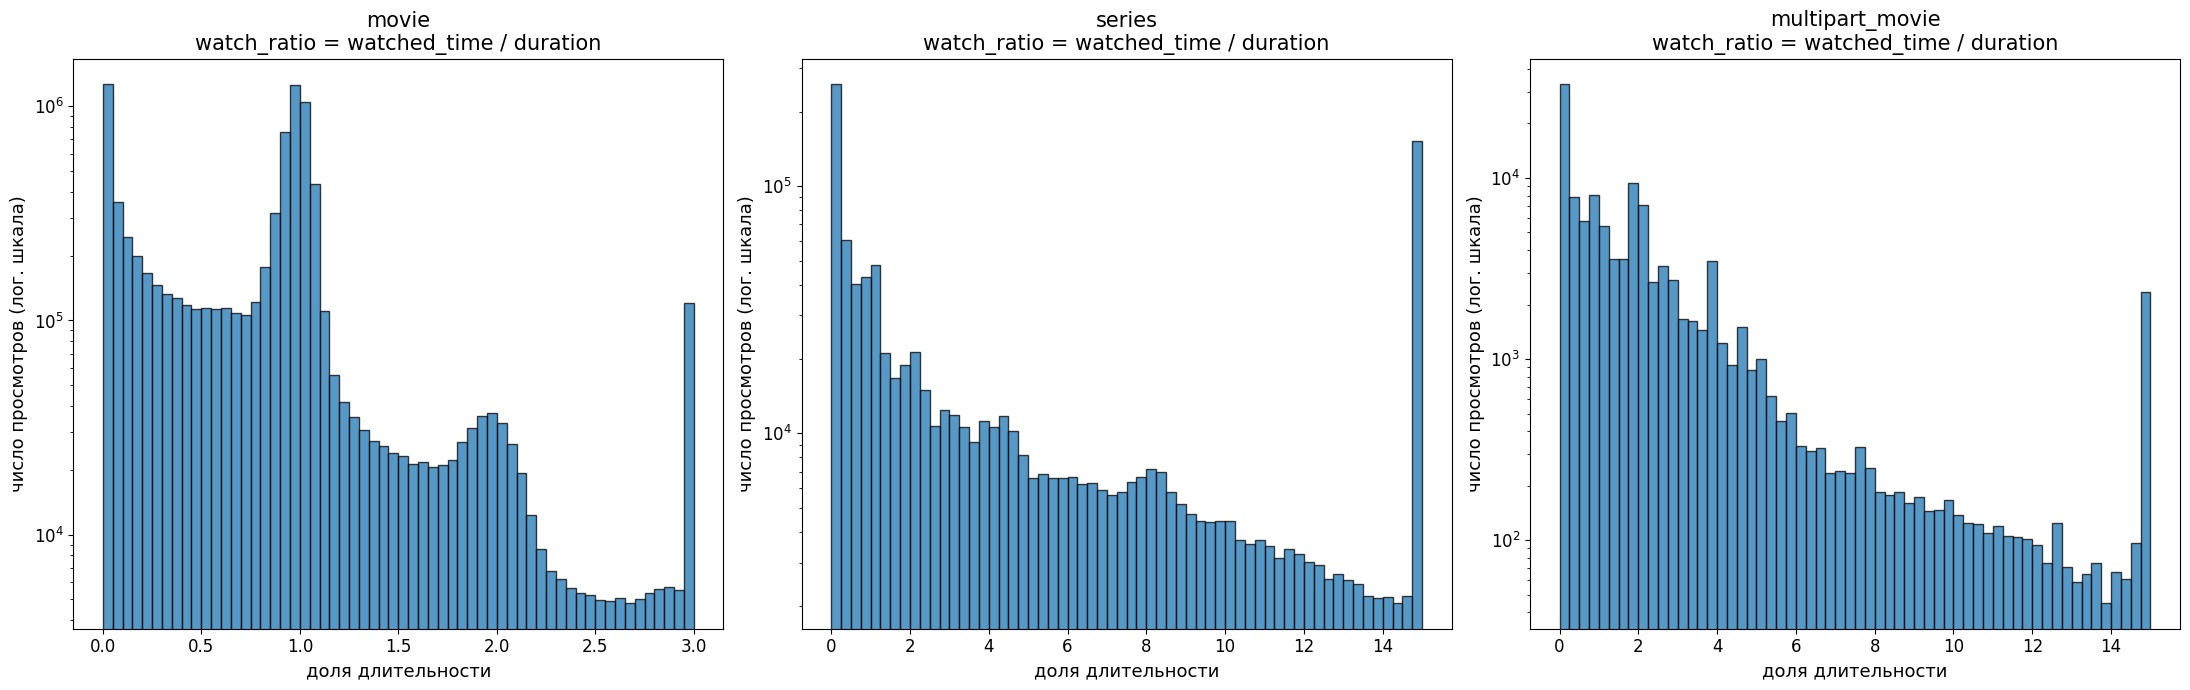

Доля досмотров: 0.651 | доля релевантных пар: 0.65
Доля просмотров < 10% длительности (брошено): 0.192


In [41]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
for t_, ax in zip(["movie", "series", "multipart_movie"], axes):
    x = df.loc[df.item_type == t_, "watch_ratio"].clip(0, 3 if t_ == "movie" else 15)
    ax.hist(x, bins=60, edgecolor="black", alpha=0.75)
    ax.set_yscale("log")
    ax.set_title(f"{t_}\nwatch_ratio = watched_time / duration", fontsize=15)
    ax.set_xlabel("доля длительности", fontsize=13)
    ax.set_ylabel("число просмотров (лог. шкала)", fontsize=13)
    ax.tick_params(labelsize=12)
plt.tight_layout(); plt.show()
print("Доля досмотров:", round(df.completed.mean(), 3), "| доля релевантных пар:", round(df.relevant.mean(), 3))
print("Доля просмотров < 10% длительности (брошено):", round((df.watch_ratio < 0.1).mean(), 3))

Интересно заметить что например для фильмов доля длительности может быть и 2,5 - это значит что пользователь например ставил на паузу фильм пока смотрел и уходил. Кроме того мы видим что для фильмов присутсвуют определнный пики (условно "не стал досматривать", "посмотрел за раз" и т.п.), дле сериалов же и сиквелов видим стабильное убывание.

Оценим насколько вообще плотая матрица взаимодействий, на основе этого будем дальше строить модели

Пользователей: 499,613, объектов: 8,205, взаимодействий: 9,537,199
Разреженность матрицы: 0.99767 (заполнено 0.233%)


,объектов на пользователя,пользователей на объект
count,499613.0,8205.0
mean,19.1,1162.4
std,25.9,3607.6
min,1.0,1.0
25%,5.0,38.0
50%,10.0,176.0
75%,22.0,751.0
90%,46.0,2430.0
99%,128.0,17306.2
max,1156.0,68320.0


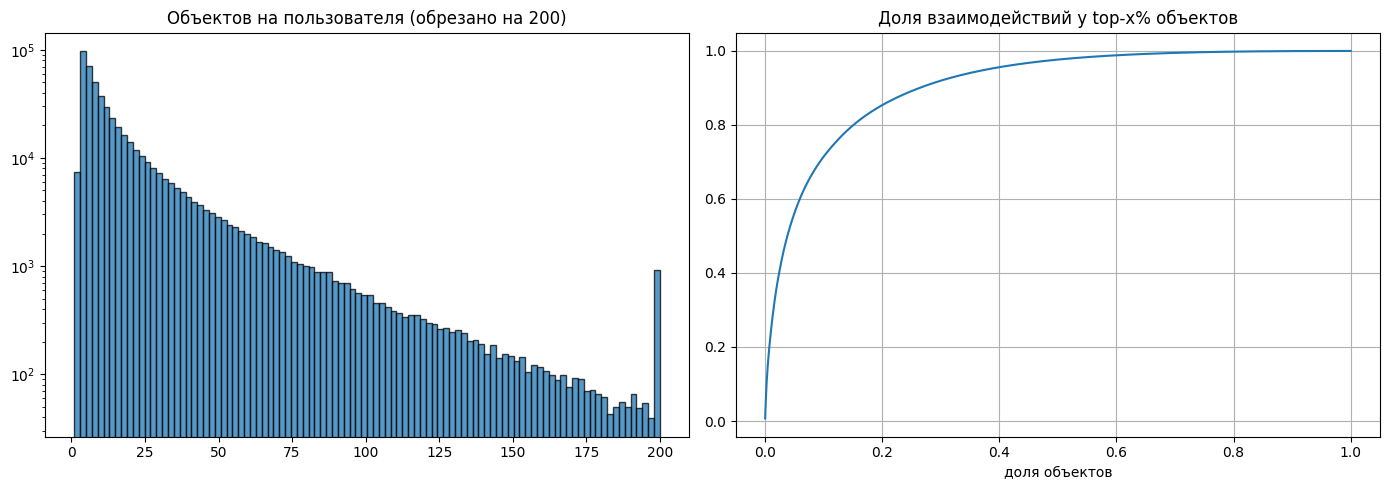

Top-1% объектов собирают 24.6% просмотров, top-10% — 71.5%


In [42]:
user_cnt = df.groupby("user_id").size()
item_cnt = df.groupby("item_id").size()
n_u, n_i = df.user_id.nunique(), df.item_id.nunique()
print(f"Пользователей: {n_u:,}, объектов: {n_i:,}, взаимодействий: {len(df):,}")
print(f"Разреженность матрицы: {1 - len(df) / (n_u * n_i):.5f} (заполнено {len(df) / (n_u * n_i) * 100:.3f}%)")
display(pd.DataFrame({"объектов на пользователя": user_cnt.describe(percentiles=[.25, .5, .75, .9, .99]),
                      "пользователей на объект": item_cnt.describe(percentiles=[.25, .5, .75, .9, .99])}).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(user_cnt.clip(upper=200), bins=100, edgecolor="black", alpha=0.75); axes[0].set_yscale("log")
axes[0].set_title("Объектов на пользователя (обрезано на 200)")
srt = np.sort(item_cnt.to_numpy())[::-1]
share = np.cumsum(srt) / srt.sum()
axes[1].plot(np.arange(1, len(srt) + 1) / len(srt), share)
axes[1].set_title("Доля взаимодействий у top-x% объектов"); axes[1].set_xlabel("доля объектов"); axes[1].grid(True)
plt.tight_layout(); plt.show()
print(f"Top-1% объектов собирают {share[int(0.01 * len(srt))]:.1%} просмотров, top-10% — {share[int(0.1 * len(srt))]:.1%}")

Мы видим, что большую часть всех взаимодействий берут на себя всего то 20% самых популярных айтемов.

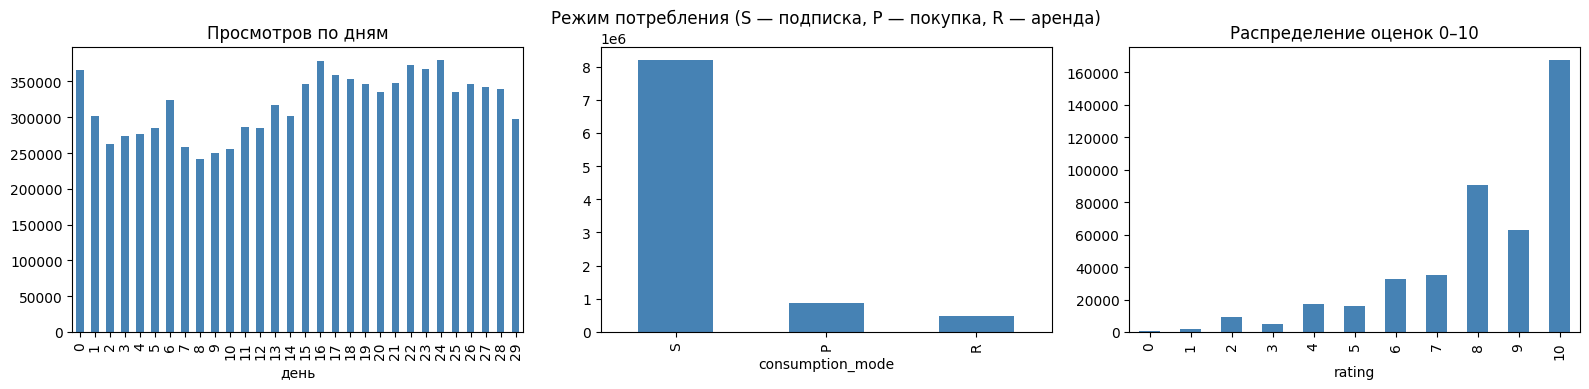

Доля пар просмотра с оценкой: 0.0374 | с закладкой: 0.0277
Оценок без просмотра: 0.186 | закладок без просмотра: 0.721


In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("day").size().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Просмотров по дням"); axes[0].set_xlabel("день")
df.consumption_mode.value_counts().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Режим потребления (S — подписка, P — покупка, R — аренда)")
r_raw.rating.value_counts().sort_index().plot(kind="bar", ax=axes[2], color="steelblue")
axes[2].set_title("Распределение оценок 0–10")
plt.tight_layout(); plt.show()
print("Доля пар просмотра с оценкой:", round(df.rating.notna().mean(), 4),
      "| с закладкой:", round(df.bookmarked.mean(), 4))
pairs_t = pd.MultiIndex.from_frame(tr_raw[["user_uid", "element_uid"]])
print("Оценок без просмотра:", round(1 - pd.MultiIndex.from_frame(r_raw[["user_uid", "element_uid"]]).isin(pairs_t).mean(), 3),
      "| закладок без просмотра:", round(1 - pd.MultiIndex.from_frame(b_raw[["user_uid", "element_uid"]]).isin(pairs_t).mean(), 3))

Видим, что распределение по дням равномерно, львиная доля просмотров идет по подписке и большинство пользователей ставят высокие оценки

Также посмотрим на сами айтемы, что он из себя представляют

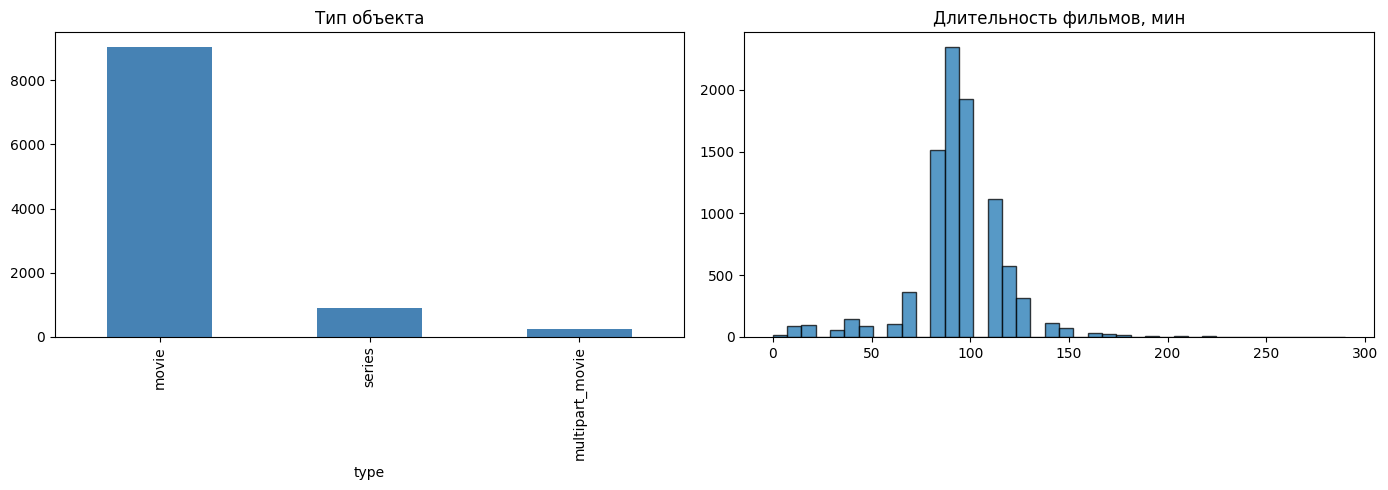

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cat.type.value_counts().plot(kind="bar", ax=axes[0], color="steelblue"); axes[0].set_title("Тип объекта")
axes[1].hist(cat.loc[cat.type == "movie", "duration"], bins=40, edgecolor="black", alpha=0.75); axes[1].set_title("Длительность фильмов, мин")
plt.tight_layout(); plt.show()
attr_freq = cat.attributes.explode().value_counts()

## Очистка и разбиение датасета

Сначала выделим тестовую и тренировочную выборки. Для обучающией берем только первые 20 дней, валидировать и тестировать модели уже будем на оставшихся 10. Оставим из них только пользователей с хотя бы 5 объектами и из оставшихся выберем случайные 60 тыс. \
По айтемам мы будем смотреть только те, которые выбирали хотя бы 10 пользователей. Учимся только на вазимодействиях выбранных айтемов и юзеров.

In [45]:
sub = make_subsample(df, CONFIG["n_users"], SEED, CONFIG["train_end_day"],
                     CONFIG["min_user_items"], CONFIG["min_item_users"])
size_table = pd.DataFrame({
    "исходные данные": [len(df), df.user_id.nunique(), df.item_id.nunique()],
    "подвыборка": [len(sub), sub.user_id.nunique(), sub.item_id.nunique()],
}, index=["взаимодействий", "пользователей", "объектов"])
display(size_table)
print(f"Разреженность подвыборки: {1 - len(sub) / (sub.user_id.nunique() * sub.item_id.nunique()):.5f}")
assert 100_000 <= len(sub) <= 2_000_000 and sub.user_id.nunique() >= 1000 and sub.item_id.nunique() >= 1000
lost = df[df.user_id.isin(sub.user_id) & ~df.item_id.isin(sub.item_id) & (df.day >= CONFIG["train_end_day"])]
print(f"Взаимодействий выбранных пользователей в val/test с отфильтрованными (редкими или новыми) объектами: "
      f"{len(lost):,} ({len(lost) / len(sub[sub.day >= CONFIG['train_end_day']]):.1%} от val/test подвыборки)")

import gc
df_sel = df[df.user_id.isin(sub.user_id)].copy()
del df, tr_raw, lost
raw["transactions"] = None
gc.collect();

,исходные данные,подвыборка
взаимодействий,9537199,1581047
пользователей,499613,60000
объектов,8205,5155


Разреженность подвыборки: 0.99489
Взаимодействий выбранных пользователей в val/test с отфильтрованными (редкими или новыми) объектами: 31,828 (8.1% от val/test подвыборки)


Итого разобъем рзаибение выберем времиенное таким образом:

| Часть | Дни | Назначение |
|---|---|---|
| train | 0–19 | обучение при подборе гиперпараметров |
| validation | 20–24 | подбор гиперпараметров |
| test | 25–29 | финальное сравнение: модели переобучаются на train + validation (дни 0–24) с выбранными настройками 

In [46]:
from src.evaluation import make_split, evaluate

train, val, test = temporal_split(sub, CONFIG["train_end_day"], CONFIG["val_end_day"])
split_val = make_split(train, val)  
split_test = make_split(pd.concat([train, val]), test)        
display(pd.DataFrame({"validation": split_val.stats, "test": split_test.stats}))
print("Пользователей / объектов в истории: val —", split_val.n_users, "/", split_val.n_items,
      "| test —", split_test.n_users, "/", split_test.n_items)

,validation,test
history_interactions,1186330.0,1410232.0
target_interactions,223902.0,170815.0
target_relevant,150104.0,114580.0
relevant_cold_user_or_item_share,0.0,0.0
eval_users,27163.0,22089.0
eval_relevant_pairs,150104.0,114580.0


Пользователей / объектов в истории: val — 60000 / 5155 | test — 60000 / 5155


## Построение моделей

In [47]:
from src.tuning import tune
from models.popular import Popular
from models.knn import ItemKNN
from models.ease import EASE
from models.ials import ImplicitALS
from models.fm import FactorizationMachine
from models.timesvdpp import TimeSVDpp
from src.features import item_features, user_features

val_results, best_params, tuning_tables = {}, {}, {}

def show_top(trials, cols, n=5):
    """Топ-n попыток подбора: подбираемые параметры + метрики на validation."""
    top = trials[cols + ["NDCG@10", "Recall@10", "Precision@10", "HitRate@10", "fit_sec"]].head(n).round(4)
    top = top.rename(columns={"k_neighbors": "k (число соседей)"})
    top.index = range(1, len(top) + 1)
    top.index.name = "место"
    display(top)


Бейзлайном у нас будет рекмендация самых популярных объектов в истории

In [48]:
pop = Popular().fit(split_val.X)
val_results["Popular"] = evaluate(pop, split_val)
val_results["Popular"]

{'NDCG@10': 0.029769153067551592,
 'Recall@10': 0.04443348766324873,
 'Precision@10': 0.020156094687626552,
 'HitRate@10': 0.16805949269226522,
 'predict_sec': 6.3}

HitRate@10 - это доля пользователей у которых в топ 10 попал хотя бы 1 релевантый объект

### KNN


$$
\text{cosine}(i,j) = \frac{\langle x_i, x_j\rangle}{\lVert x_i\rVert\,\lVert x_j\rVert + s},\qquad
\text{jaccard}(i,j) = \frac{|U_i \cap U_j|}{|U_i \cup U_j| + s},
$$

где $s$ добавляется для того чтобы не учитывать пары с малым числом общих пользователей 

$$
\text{score}(u,i) = \sum_{j \in I_u} \text{sim}(i,j)\,[i \in N_k(j)].
$$

берем item-based вариант т.к. объектов (5 тыс.) на порядок меньше, чем пользователей (60 тыс.), айтемы будут более стабильные и логичнее использовать i2i

Теперь запуустим knn и попробуем подобрать гиперпараметр k

In [49]:
def knn_space(trial):
    return {"k_neighbors": trial.suggest_int("k_neighbors", 10, 1000, log=True),
            "similarity": trial.suggest_categorical("similarity", ["cosine", "jaccard"]),
            "shrink": trial.suggest_float("shrink", 0.0, 200.0)}

t = time.time()
best, trials = tune(lambda p: ItemKNN(**p), knn_space, split_val, CONFIG["n_trials"]["knn"], SEED,
                     cache=f"{CONFIG['cache_dir']}/tuning_knn.csv")
best_params["ItemKNN"], tuning_tables["ItemKNN"] = best, trials
val_results["ItemKNN"] = trials.iloc[0][list(val_results["Popular"].keys())].to_dict()
print(f"{time.time() - t:.0f} c; лучшие параметры:", best)
show_top(trials, ["k_neighbors", "similarity", "shrink"])

[кеш] результаты подбора прочитаны из cache/tuning_knn.csv
0 c; лучшие параметры: {'k_neighbors': 730, 'similarity': 'jaccard', 'shrink': 7.745039992236585}


,k (число соседей),similarity,shrink,NDCG@10,Recall@10,Precision@10,HitRate@10,fit_sec
место,,,,,,,,
1,730,jaccard,7.7450,0.0549,0.0753,0.0323,0.2465,1.2
2,802,jaccard,1.5095,0.0549,0.0751,0.0323,0.2465,1.2
3,981,jaccard,0.9336,0.0548,0.0749,0.0323,0.2465,1.3
4,631,jaccard,14.5541,0.0548,0.0751,0.0322,0.2464,1.3
5,927,jaccard,3.6945,0.0547,0.0748,0.0322,0.2460,1.3


успех, бейзлайн превышен

### ALS
Берем  implicit, т.к. оценок пользователей крайне мало
$$
p_{ui} = [\,(u,i)\ \text{наблюдалась}\,],\qquad c_{ui} = 1 + \alpha\, r_{ui}
$$

$$
\min_{X,Y} \sum_{u,i} c_{ui}\,(p_{ui} - x_u^\top y_i)^2 + \lambda\Big(\sum_u \lVert x_u\rVert^2 + \sum_i \lVert y_i\rVert^2\Big).
$$

Формула для итеративноого подсчета шага ALS

$$
x_u = \Big(Y^\top Y + \sum_{i \in I_u} (c_{ui}-1)\, y_i y_i^\top + \lambda I\Big)^{-1} \sum_{i \in I_u} c_{ui}\, p_{ui}\, y_i ,
$$

Будем искать оптимум среди числа факторов ∈ {8, 16, 32, 64}, $\lambda \in [10^{-2}, 10^{4}]$, $\alpha \in [0.05, 50]$

In [50]:
IALS_START = {"n_factors": 32, "reg": 87.0, "alpha": 1.1}   # лучшая точка пробного запуска

def ials_space(trial):
    return {"n_factors": trial.suggest_categorical("n_factors", [8, 16, 32, 64]),
            "reg": trial.suggest_float("reg", 1e-2, 1e4, log=True),
            "alpha": trial.suggest_float("alpha", 0.05, 50.0, log=True)}

t = time.time()
best, trials = tune(lambda p: ImplicitALS(n_iters=10, random_state=SEED, **p), ials_space, split_val,
                     CONFIG["n_trials"]["ials"], SEED,
                     cache=f"{CONFIG['cache_dir']}/tuning_ials.csv", enqueue=[IALS_START])
best_params["iALS"], tuning_tables["iALS"] = best, trials
val_results["iALS"] = trials.iloc[0][list(val_results["Popular"].keys())].to_dict()
print(f"{time.time() - t:.0f} c; лучшие параметры:", best)
show_top(trials, ["n_factors", "reg", "alpha"])

[кеш] результаты подбора прочитаны из cache/tuning_ials.csv
0 c; лучшие параметры: {'n_factors': 32, 'reg': 87.0, 'alpha': 1.1}


,n_factors,reg,alpha,NDCG@10,Recall@10,Precision@10,HitRate@10,fit_sec
место,,,,,,,,
1,32,87.0000,1.1000,0.0536,0.0730,0.0313,0.2393,4.1
2,64,135.1568,7.3038,0.0535,0.0719,0.0306,0.2382,13.5
3,64,112.6565,7.3796,0.0526,0.0708,0.0300,0.2340,13.1
4,16,0.7418,1.8162,0.0519,0.0710,0.0305,0.2369,2.1
5,16,35.8499,0.0689,0.0507,0.0689,0.0296,0.2304,1.6


результаты чуть хуже чем у простого KNN

### EASE

$$
\min_B \lVert X - XB\rVert_F^2 + \lambda \lVert B\rVert_F^2 \quad \text{при}\quad \operatorname{diag}(B) = 0 .
$$

Решение: $\hat P = (X^\top X + \lambda I)^{-1}$, $\;B_{ij} = -\hat P_{ij} / \hat P_{jj}$ ($i \ne j$),
$B_{jj} = 0$; скоры — $X_u B$. Выбрал EASE вместо SLIM, поскольку его проще реализовывать

In [51]:
def ease_space(trial):
    return {"reg": trial.suggest_float("reg", 1.0, 1e4, log=True)}

t = time.time()
best, trials = tune(lambda p: EASE(**p), ease_space, split_val, CONFIG["n_trials"]["ease"], SEED,
                     cache=f"{CONFIG['cache_dir']}/tuning_ease.csv")
best_params["EASE"], tuning_tables["EASE"] = best, trials
val_results["EASE"] = trials.iloc[0][list(val_results["Popular"].keys())].to_dict()
print(f"{time.time() - t:.0f} c; лучшие параметры:", best)
show_top(trials, ["reg"])

[кеш] результаты подбора прочитаны из cache/tuning_ease.csv
0 c; лучшие параметры: {'reg': 679.6578090758157}


,reg,NDCG@10,Recall@10,Precision@10,HitRate@10,fit_sec
место,,,,,,
1,679.6578,0.0578,0.0781,0.0333,0.2544,4.4
2,1128.1509,0.0577,0.0787,0.0335,0.2555,4.5
3,847.1801,0.0577,0.0782,0.0333,0.2548,4.3
4,253.7816,0.0575,0.0780,0.0331,0.2542,4.3
5,248.1041,0.0574,0.0780,0.0331,0.2539,4.2


Немногим лучше чем лидирующий до этого KNN, но все равно они все примерно одинаковые если смотреть глобально

### FM

$$
\hat y(x) = w_0 + \sum_f w_f x_f + \sum_{f<g} \langle v_f, v_g\rangle x_f x_g
= w_0 + \sum_f w_f x_f + \tfrac12 \sum_{d=1}^{k}\Big[\big(\textstyle\sum_f v_{fd}x_f\big)^2 - \sum_f v_{fd}^2 x_f^2\Big].
$$


Лосс используем как BPR

$$
\mathcal L = -\sum_{(u,i,j)} \log \sigma\big(\hat y(u,i) - \hat y(u,j)\big) + \lambda\big(\lVert e_u\rVert^2 + \lVert e_i\rVert^2 + \lVert e_j\rVert^2\big),
$$

Будем использовать следующие признаки:

Юзер: `user_uid`, число просмотров в истории `transactions`, тип просмотра подписка/неподписка `consumption_mode`, устройство `device_type`, доля сериалов среди просмотренного. \

Айтем: `element_uid`, `type` (movie / series / multipart_movie), `availability` (purchase / rent / subscription), корзины `duration`, `feature_2`, `feature_3`, `feature_4` и `feature_5` из каталога; наиболее частые `attributes`

In [52]:
IF_val, item_feat_names = item_features(split_val, cat)
UF_val, user_feat_names = user_features(split_val)
print("Признаки объектов:", IF_val.shape, "| признаки пользователей:", UF_val.shape)
print("Группы признаков объектов:", pd.Series([n.rsplit("_", 1)[0] for n in item_feat_names]).value_counts().to_dict())
print("Группы признаков пользователей:", pd.Series([n.rsplit("_", 1)[0] for n in user_feat_names]).value_counts().to_dict())

def fm_space(trial):
    return {"n_factors": trial.suggest_categorical("n_factors", [32, 64]),
            "lr": trial.suggest_float("lr", 5e-4, 5e-3, log=True),
            "reg": trial.suggest_float("reg", 1e-5, 1e-2, log=True),
            "n_epochs": trial.suggest_int("n_epochs", 4, 16)}

t = time.time()
best, trials = tune(lambda p: FactorizationMachine(batch_size=8192, random_state=SEED, **p), fm_space, split_val,
                     CONFIG["n_trials"]["fm"], SEED,
                     fit_kwargs={"user_features": UF_val, "item_features": IF_val},
                     cache=f"{CONFIG['cache_dir']}/tuning_fm.csv")
best_params["FM"], tuning_tables["FM"] = best, trials
val_results["FM"] = trials.iloc[0][list(val_results["Popular"].keys())].to_dict()
print(f"{time.time() - t:.0f} c; лучшие параметры:", best)
show_top(trials, ["n_factors", "lr", "reg", "n_epochs"])

Признаки объектов: (5155, 5318) | признаки пользователей: (60000, 60016)
Группы признаков объектов: {'item_id': 5155, 'attr': 106, 'pop_q': 10, 'pop_recent_q': 10, 'feature_5': 6, 'duration_q': 5, 'age_q': 5, 'feature_2_q': 5, 'feature_3_q': 5, 'feature_4_q': 5, 'type': 3, 'avail': 3}
Группы признаков пользователей: {'user_id': 60000, 'device': 7, 'activity_q': 5, 'mode_share': 3, 'series_share': 1}
[кеш] результаты подбора прочитаны из cache/tuning_fm.csv
0 c; лучшие параметры: {'n_factors': 64, 'lr': 0.0016738881542579659, 'reg': 0.00019762189340280086, 'n_epochs': 7}


,n_factors,lr,reg,n_epochs,NDCG@10,Recall@10,Precision@10,HitRate@10,fit_sec
место,,,,,,,,,
1,64,0.0017,0.0002,7,0.0497,0.0689,0.0281,0.2265,109.0
2,32,0.0037,0.0006,13,0.0472,0.0644,0.0278,0.2220,142.7
3,64,0.0027,0.0006,6,0.0467,0.0660,0.0279,0.2238,97.8
4,64,0.0012,0.0000,12,0.0466,0.0658,0.0272,0.2196,165.4
5,64,0.0034,0.0000,6,0.0462,0.0655,0.0273,0.2197,92.4


Интересно что пока это самое худшее качество... Возможно дело в избыточной параметризации и неправильном выборе параметров в целом.

###  timeSVD++


$$
\hat y_{ui}(t) = b_i + b_{i,\text{bin}(t)} + q_i^\top\Big(p_u + \alpha_u \cdot \text{dev}_u(t) + |N(u)|^{-1/2}\sum_{j \in N(u)} y_j\Big),
\qquad \text{dev}_u(t) = \text{sign}(t-\bar t_u)\,|t-\bar t_u|^{\beta},\ \ \beta = 0.4.
$$

Будем брать бины по 4 дня (всего 5 бинов), а $b_i + b_{i,\text{bin}(t)}$ - общее и смещение по бинам соответсвенно

Т.к. метод предсказывает оценки, а самих оценок у нас нет, то будем как и в случае FM использовать BPR, для обучения ранжированию.Смещение юзера однаково для всех обхектов рандирования и в формулу не входит.



In [54]:
def tsvd_space(trial):
    return {"n_factors": trial.suggest_categorical("n_factors", [32, 64]),
            "lr": trial.suggest_float("lr", 1e-3, 1e-2, log=True),
            "reg": trial.suggest_float("reg", 1e-5, 1e-2, log=True),
            "n_epochs": trial.suggest_int("n_epochs", 4, 12)}

t = time.time()
best, trials = tune(lambda p: TimeSVDpp(batch_size=16384, random_state=SEED, **p), tsvd_space, split_val,
                    CONFIG["n_trials"]["timesvdpp"], SEED, fit_kwargs={"split": split_val},
                    cache=f"{CONFIG['cache_dir']}/tuning_timesvdpp.csv")
best_params["timeSVD++"], tuning_tables["timeSVD++"] = best, trials
val_results["timeSVD++"] = trials.iloc[0][list(val_results["Popular"].keys())].to_dict()
print(f"{time.time() - t:.0f} c; лучшие параметры:", best)
show_top(trials, ["n_factors", "lr", "reg", "n_epochs"])


1341 c; лучшие параметры: {'n_factors': 64, 'lr': 0.00539503096667023, 'reg': 0.0006251373574521745, 'n_epochs': 5}


,n_factors,lr,reg,n_epochs,NDCG@10,Recall@10,Precision@10,HitRate@10,fit_sec
место,,,,,,,,,
1,64,0.0054,0.0006,5,0.0626,0.0817,0.0342,0.2637,97.1
2,64,0.0068,0.0000,5,0.0619,0.0814,0.0338,0.2601,93.5
3,64,0.0033,0.0002,6,0.0614,0.0825,0.0343,0.2648,137.4
4,64,0.0081,0.0000,4,0.0610,0.0816,0.0340,0.2613,74.1
5,64,0.0053,0.0000,10,0.0597,0.0811,0.0336,0.2574,191.8


## Сравнение на validation

In [55]:
val_table = pd.DataFrame(val_results).T[["NDCG@10", "Recall@10", "Precision@10", "HitRate@10"]]
display(val_table.astype(float).round(4).sort_values("NDCG@10", ascending=False))
pd.Series({m: str(p) for m, p in best_params.items()}, name="выбранные гиперпараметры").to_frame()

,NDCG@10,Recall@10,Precision@10,HitRate@10
timeSVD++,0.0626,0.0817,0.0342,0.2637
EASE,0.0578,0.0781,0.0333,0.2544
ItemKNN,0.0549,0.0753,0.0323,0.2465
iALS,0.0536,0.0730,0.0313,0.2393
FM,0.0497,0.0689,0.0281,0.2265
Popular,0.0298,0.0444,0.0202,0.1681


,выбранные гиперпараметры
ItemKNN,"{'k_neighbors': 730, 'similarity': 'jaccard', ..."
iALS,"{'n_factors': 32, 'reg': 87.0, 'alpha': 1.1}"
EASE,{'reg': 679.6578090758157}
FM,"{'n_factors': 64, 'lr': 0.0016738881542579659,..."
timeSVD++,"{'n_factors': 64, 'lr': 0.00539503096667023, '..."


видим что модель timeSVD++ показала лучшие резульатты на валидации, значит скорее всего учитывать "тренды" и и зименение предпочтений во времени имеет смысл на реальных данных

## Сравнение на test 

Переобучим модели заново уже на train + validation и посмотрим на тест: 


In [56]:
IF_test, _ = item_features(split_test, cat)
UF_test, _ = user_features(split_test)
tsvd_fit_test = {"split": split_test}

final_models = {
    "Popular": (Popular(), {}),
    "ItemKNN": (ItemKNN(**best_params["ItemKNN"]), {}),
    "iALS": (ImplicitALS(n_iters=10, random_state=SEED, **best_params["iALS"]), {}),
    "EASE": (EASE(**best_params["EASE"]), {}),
    "FM": (FactorizationMachine(batch_size=8192, random_state=SEED, **best_params["FM"]),
           {"user_features": UF_test, "item_features": IF_test}),
    "timeSVD++": (TimeSVDpp(batch_size=16384, random_state=SEED, **best_params["timeSVD++"]), tsvd_fit_test),
}
from src.evaluation import recommend_all
test_results, test_recs = {}, {}
for name, (model, fit_kw) in final_models.items():
    t = time.time()
    model.fit(split_test.X, **fit_kw)
    test_recs[name] = recommend_all(model, split_test, K)
    res = evaluate(model, split_test)
    res["fit_sec"] = max(0.0, round(time.time() - t - res["predict_sec"], 1))
    test_results[name] = res
    print(f"{name:38s} NDCG@10={res['NDCG@10']:.4f}  Recall@10={res['Recall@10']:.4f}  ({res['fit_sec']} c)")

Popular                                NDCG@10=0.0262  Recall@10=0.0383  (3.1 c)
ItemKNN                                NDCG@10=0.0595  Recall@10=0.0784  (10.7 c)
iALS                                   NDCG@10=0.0542  Recall@10=0.0740  (14.5 c)
EASE                                   NDCG@10=0.0572  Recall@10=0.0808  (17.5 c)
FM                                     NDCG@10=0.0409  Recall@10=0.0598  (181.1 c)
timeSVD++                              NDCG@10=0.0592  Recall@10=0.0783  (127.5 c)
FM (только ID)                         NDCG@10=0.0382  Recall@10=0.0564  (66.3 c)


In [59]:
main_models = ["Popular", "ItemKNN", "iALS", "EASE", "FM", "timeSVD++"]
cols = ["NDCG@10", "Recall@10", "Precision@10", "HitRate@10", "fit_sec"]
test_table = pd.DataFrame(test_results).T[cols].astype(float)
final_table = test_table.loc[main_models].copy()
final_table["гиперпараметры"] = [("—" if m == "Popular" else str({k: (round(v, 4) if isinstance(v, float) else v)
                                  for k, v in best_params[m].items()})) for m in main_models]
final_table = final_table.sort_values("NDCG@10", ascending=False)
print("Test (дни 25–29), модели обучены на днях 0–24; K = 10")
display(final_table.round(4))

Test (дни 25–29), модели обучены на днях 0–24; K = 10


,NDCG@10,Recall@10,Precision@10,HitRate@10,fit_sec,гиперпараметры
ItemKNN,0.0595,0.0784,0.0307,0.2377,10.7,"{'k_neighbors': 730, 'similarity': 'jaccard', ..."
timeSVD++,0.0592,0.0783,0.0307,0.2418,127.5,"{'n_factors': 64, 'lr': 0.0054, 'reg': 0.0006,..."
EASE,0.0572,0.0808,0.0309,0.2436,17.5,{'reg': 679.6578}
iALS,0.0542,0.0740,0.0289,0.2278,14.5,"{'n_factors': 32, 'reg': 87.0, 'alpha': 1.1}"
FM,0.0409,0.0598,0.0232,0.1926,181.1,"{'n_factors': 64, 'lr': 0.0017, 'reg': 0.0002,..."
Popular,0.0262,0.0383,0.0168,0.1431,3.1,—


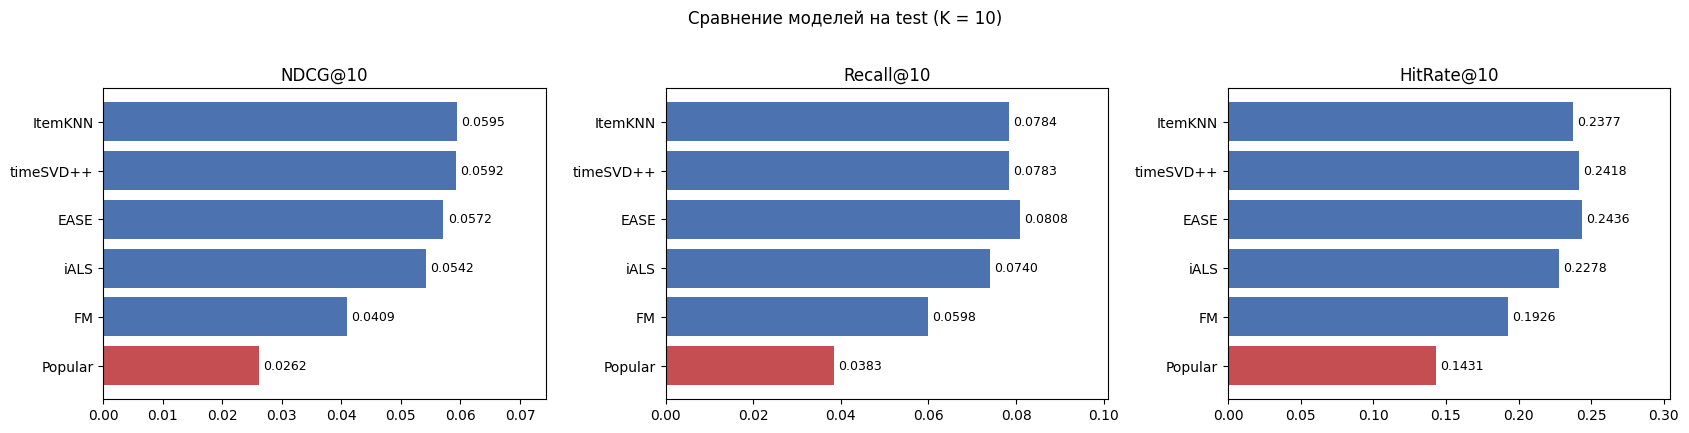

,validation,test
Popular,0.0298,0.0262
ItemKNN,0.0549,0.0595
iALS,0.0536,0.0542
EASE,0.0578,0.0572
FM,0.0497,0.0409
timeSVD++,0.0626,0.0592


In [60]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
order = final_table.index.tolist()
colors = ["#C44E52" if m == "Popular" else "#4C72B0" for m in order]
for ax, metric in zip(axes, ["NDCG@10", "Recall@10", "HitRate@10"]):
    vals = final_table.loc[order, metric]
    bars = ax.barh(order[::-1], vals[::-1], color=colors[::-1])
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
    ax.set_title(metric); ax.set_xlim(0, vals.max() * 1.25)
plt.suptitle("Сравнение моделей на test (K = 10)", y=1.02); plt.tight_layout(); plt.show()

cmp = pd.DataFrame({"validation": val_table.loc[main_models, "NDCG@10"].astype(float),
                    "test": final_table.loc[main_models, "NDCG@10"]})
display(cmp.round(4))

## 6. Выводы

Занесем итоговые результаты в табличку

| Место | Модель | NDCG@10 | Recall@10 | HitRate@10 | Выбранные настройки |
|---|---|---|---|---|---|
| 1 | Item-based kNN | **0.0595** | 0.0784 | 0.2377 | Jaccard, k = 730 соседей |
| 2 | timeSVD++ | 0.0592 | 0.0783 | 0.2418 | 64 фактора, lr = 0.0054, λ = 0.0006, 5 эпох |
| 3 | EASE | 0.0572 | **0.0808** | **0.2436** | λ ≈ 680 |
| 4 | iALS | 0.0542 | 0.0740 | 0.2278 | 32 фактора, λ = 87, α = 1.1 |
| 5 | FM с метапризнаками | 0.0409 | 0.0598 | 0.1926 | 64 фактора, lr = 0.0017, λ = 0.0002 |
| — | Popular (бейзлайн) | 0.0262 | 0.0383 | 0.1431 | — |

Напомню про ограничения в нашем эксперименте - подвыборка 60 тыс пользователей, 30 дней логов. Использовали только айтемы, с которыми вообще были какие то взаимодействия, а кратирей релевантности фильма был его просмотр хотя бы на половину и оценка 8+. 

Первое что можно заметить - все модели обошли бейзлайн. Среди лидеров имеем KNN, timeSVD++, EASE - различия между ними минимальные. Вероятнее всего эти модекли обогнали остальные, посокльку их предсказания полностью описываются на связи айтем-айтем, а поскольку число фильмов довольно большое, то модели такого рода показывают лучшие результаты, чем те, которые в большей степени опираются на "вкусовые" предпочтения пользователей.
Отдельно стоит отметить, что крайне плохие результаты показала модель FM, причем и при переходе с validation на test она потеряла больше всех по всем метрикам. Возможно это свзяано с тем, что по небольшому числу взаимоедйстви пользователя (в среднем около 20 на юзера) трудно построить веткор по ID на 64 парамтера (подобрано оптимизатором). Вероятно еще это может быть свзяано с неправильно выбранными нами признаками. Кажестя стоило влючить историю поиска как отдельный признак при обучении нашей модели, но это уже совсем другой эксперимент, требуюзий отдельного рассмотрения.

